# Online Retail - SQL analysis

Data: sales of a UK online gift shop from December 2010 to December 2011

I load the csv into SQLite, clean it with SQL, split it into 4 tables and then answer 5 questions:
1. what is wrong with the raw data
2. revenue by month
3. RFM customer segments
4. cohort retention
5. products with the most returns

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

COLOR = "#800020"        # burgundy, used in all charts
LIGHT_COLOR = "#D9A3AD"  # light burgundy for the second bar

conn = sqlite3.connect("data/online_retail.db")


def read_sql_file(path):
    with open(path) as f:
        return pd.read_sql(f.read(), conn)


def run_sql_file(path):
    with open(path) as f:
        conn.executescript(f.read())

## 1. Load the data

- `Invoice` and `StockCode` are read as text, otherwise pandas turns some codes into numbers
- `encoding="latin-1"` because the file has the £ sign and utf-8 gives an error

In [2]:
raw = pd.read_csv("data/online_retail_II.csv", dtype={"Invoice": str, "StockCode": str}, encoding="latin-1")
raw.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  object 
 1   StockCode    541910 non-null  object 
 2   Description  540456 non-null  object 
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  object 
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [4]:
raw.describe()

,Quantity,Price,Customer ID
count,541910.000000,541910.000000,406830.000000
mean,9.552234,4.611138,15287.684160
std,218.080957,96.759765,1713.603074
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


Already visible: negative Quantity and Price, and Customer ID has fewer values than the other columns.

In [5]:
raw.isna().sum()

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

In [6]:
raw["Country"].value_counts().head(10)

Country
United Kingdom    495478
Germany             9495
France              8558
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

In [7]:
# dates look like 12/1/10 8:26 - SQLite has no date type, so I save them as text 'YYYY-MM-DD HH:MM:SS'
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], format="%m/%d/%y %H:%M").dt.strftime("%Y-%m-%d %H:%M:%S")

raw.to_sql("raw_sales", conn, if_exists="replace", index=False)
print(len(raw), "rows loaded")

541910 rows loaded


## 2. Look at the problems in the data

In [8]:
# stock codes that are not normal products (normal ones start with 5 digits)
pd.read_sql('''
SELECT StockCode, MIN(Description) AS example, COUNT(*) AS n
FROM raw_sales
WHERE StockCode NOT GLOB '[0-9][0-9][0-9][0-9][0-9]*'
GROUP BY StockCode
ORDER BY n DESC
''', conn)

,StockCode,example,n
0,POST,POSTAGE,1257
1,DOT,DOTCOM POSTAGE,710
2,M,Manual,571
3,C2,CARRIAGE,144
4,D,Discount,77
5,S,SAMPLES,63
6,BANK CHARGES,Bank Charges,37
7,AMAZONFEE,AMAZON FEE,34
8,CRUK,CRUK Commission,16
9,DCGSSGIRL,GIRLS PARTY BAG,13


POST, M (manual), BANK CHARGES, AMAZONFEE, DOT and gift vouchers are not real products, so I remove them in the cleaning

In [9]:
quality = read_sql_file("sql/queries/01_data_quality.sql")
quality

,problem,n_rows
0,all rows,541910
1,no Customer ID,135080
2,cancellation (kept),9288
3,price 0 or less,2517
4,"negative quantity, not a cancellation",1336
5,"service code, not a product",2951
6,exact duplicate,5268


## 3. Cleaning

In [10]:
run_sql_file("sql/01_cleaning.sql")

clean_rows = pd.read_sql("SELECT COUNT(*) AS n FROM clean_sales", conn)["n"][0]
print("raw rows:  ", len(raw))
print("clean rows:", clean_rows)
print("kept:", round(100 * clean_rows / len(raw), 1), "%")

raw rows:   541910
clean rows: 531205
kept: 98.0 %


## 4. Split into 4 tables

In [11]:
run_sql_file("sql/02_schema.sql")
run_sql_file("sql/03_populate.sql")

pd.read_sql('''
SELECT 'customers' AS table_name, COUNT(*) AS n FROM customers
UNION ALL SELECT 'products', COUNT(*) FROM products
UNION ALL SELECT 'invoices', COUNT(*) FROM invoices
UNION ALL SELECT 'invoice_items', COUNT(*) FROM invoice_items
''', conn)

,table_name,n
0,customers,4362
1,products,3812
2,invoices,23195
3,invoice_items,531205


In [12]:
# check that no money was lost when splitting the table
pd.read_sql('''
SELECT
    (SELECT ROUND(SUM(quantity * price)) FROM clean_sales) AS total_clean_sales,
    (SELECT ROUND(SUM(quantity * price)) FROM invoice_items) AS total_invoice_items
''', conn)

,total_clean_sales,total_invoice_items
0,9771318.0,9771318.0


## 5. Analysis

### Revenue by month

In [13]:
monthly = read_sql_file("sql/queries/02_monthly_revenue.sql")
monthly

,month,revenue,cancelled,cancel_pct,n_invoices,growth_pct
0,2010-12,775638.0,17548.0,2.3,1851,NaN
1,2011-01,670380.0,91525.0,13.7,1328,-13.6
2,2011-02,507800.0,8336.0,1.6,1284,-24.3
3,2011-03,689834.0,10504.0,1.5,1721,35.8
4,2011-04,515378.0,33316.0,6.5,1455,-25.3
5,2011-05,739953.0,8948.0,1.2,1935,43.6
6,2011-06,737559.0,13714.0,1.9,1824,-0.3
7,2011-07,688219.0,11407.0,1.7,1688,-6.7
8,2011-08,724217.0,22927.0,3.2,1579,5.2
9,2011-09,1028320.0,16981.0,1.7,2117,42.0


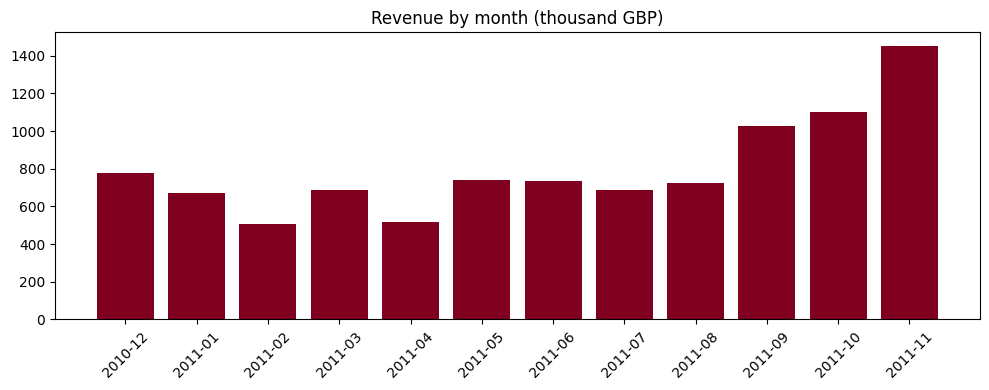

In [14]:
# December 2011 has only 9 days of data, so I don't show it on the chart
chart = monthly[monthly["month"] != "2011-12"]

plt.figure(figsize=(10, 4))
plt.bar(chart["month"], chart["revenue"] / 1000, color=COLOR)
plt.title("Revenue by month (thousand GBP)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("images/monthly_revenue.png", dpi=120)
plt.show()

Revenue is around 500-750k per month in the first half of the year and then grows a lot from September. November 2011 is the best month (1.45M), probably because shops buy gifts before Christmas.

Cancellations are usually under 4% of revenue (April 6.5%), but January 2011 (13.7%) and December 2011 (28.3%) are much higher. I checked it and it is mostly one very big order in each month that was cancelled right away (see the returns section below). These orders are also included in the revenue of those months (77k in January, 168k in December), so the real revenue there is a bit lower.

### RFM customer segments

In [15]:
rfm = read_sql_file("sql/queries/03_rfm_segments.sql")
rfm

,segment,customers,pct_customers,avg_recency,avg_orders,avg_spent,pct_revenue
0,Champions,821,18.9,12.0,12.3,6558.0,61.6
1,Loyal,791,18.3,32.0,4.4,1728.0,15.6
2,Hibernating,1348,31.1,208.0,1.3,504.0,7.8
3,At risk,386,8.9,135.0,4.3,1655.0,7.3
4,Potential loyalists,756,17.4,38.0,1.6,786.0,6.8
5,New,232,5.4,18.0,1.0,317.0,0.8


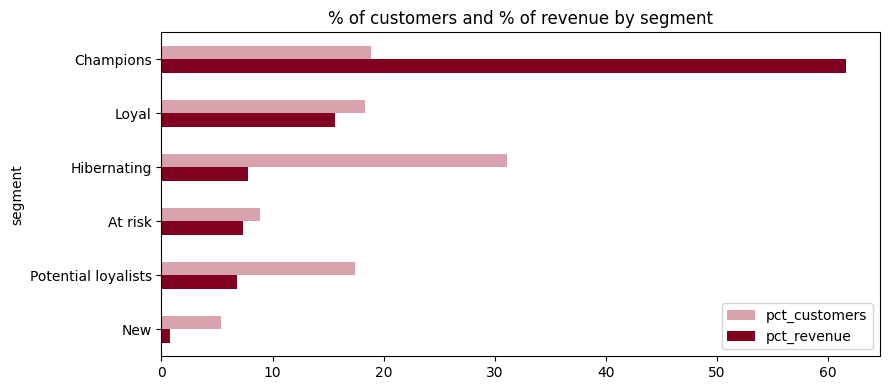

In [16]:
rfm_chart = rfm.set_index("segment")[["pct_customers", "pct_revenue"]]
rfm_chart.plot(kind="barh", figsize=(9, 4), color=[LIGHT_COLOR, COLOR])
plt.title("% of customers and % of revenue by segment")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("images/rfm_segments.png", dpi=120)
plt.show()

Champions are only 19% of customers but bring 62% of the revenue. Hibernating customers are the biggest group (31%) but bring less than 8%

Ideas: some loyalty bonus for Champions, and a personal offer for "At risk" customers. They used to buy often (4.3 orders on average) but have not come back for ~4 months

### Cohort retention

In [17]:
cohorts = read_sql_file("sql/queries/04_cohort_retention.sql")

# table: rows = cohort, columns = months after first purchase
retention = cohorts.pivot(index="cohort", columns="month_number", values="retention_pct")
retention

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort,,,,,,,,,,,,,
2010-12,100.0,36.5,32.4,38.3,36.2,39.8,36.2,34.8,35.3,39.5,37.3,50.2,26.5
2011-01,100.0,21.9,26.7,22.8,31.7,28.8,24.8,24.0,29.6,32.7,36.5,11.8,NaN
2011-02,100.0,18.7,18.7,28.7,27.1,24.5,25.5,27.4,24.7,30.5,6.8,NaN,NaN
2011-03,100.0,14.8,25.2,19.9,22.3,16.8,26.8,23.0,27.9,8.6,NaN,NaN,NaN
2011-04,100.0,21.0,20.3,21.0,19.7,22.7,21.7,26.0,7.3,NaN,NaN,NaN,NaN
2011-05,100.0,19.0,17.3,17.3,20.8,23.2,26.4,9.5,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.4,15.7,26.4,23.1,33.1,9.5,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,17.6,20.3,22.5,27.3,11.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.1,24.3,24.3,12.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


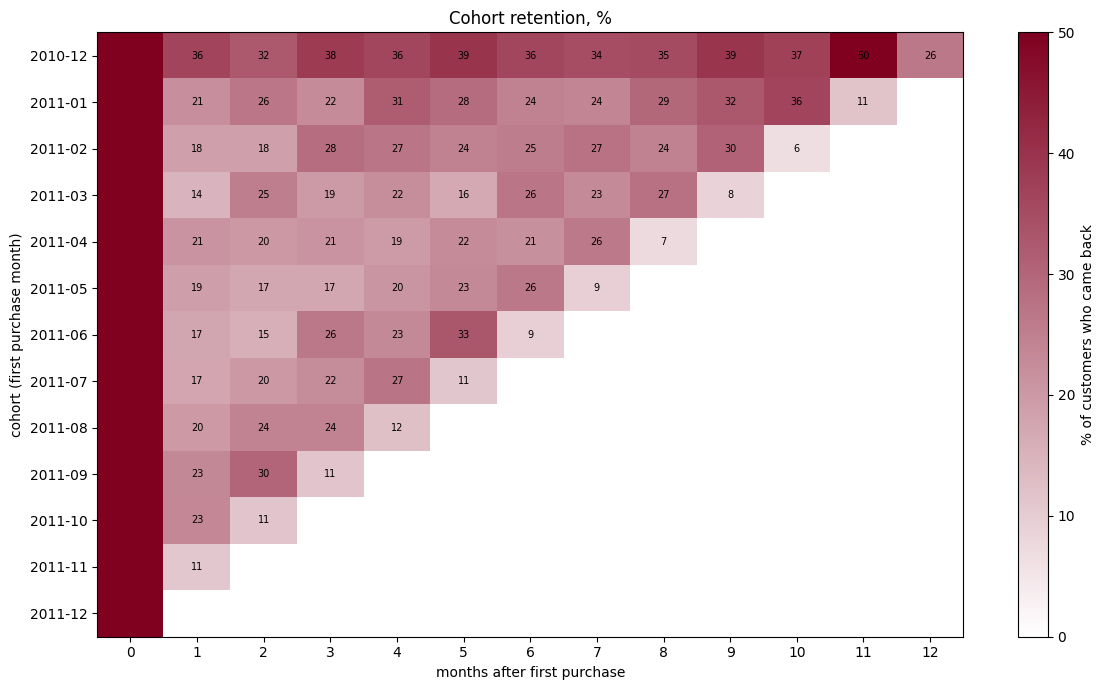

In [18]:
from matplotlib.colors import LinearSegmentedColormap

burgundy_cmap = LinearSegmentedColormap.from_list("burgundy", ["white", COLOR])

plt.figure(figsize=(12, 7))
plt.imshow(retention, cmap=burgundy_cmap, vmin=0, vmax=50, aspect="auto")
plt.colorbar(label="% of customers who came back")
plt.xticks(range(len(retention.columns)), retention.columns)
plt.yticks(range(len(retention.index)), retention.index)
plt.xlabel("months after first purchase")
plt.ylabel("cohort (first purchase month)")
plt.title("Cohort retention, %")

# write the numbers in the cells (month 0 is always 100, so I skip it)
for row in range(len(retention.index)):
    for col in range(1, len(retention.columns)):
        value = retention.iloc[row, col]
        if not pd.isna(value):
            plt.text(col, row, int(value), ha="center", va="center", fontsize=7)

plt.tight_layout()
plt.savefig("images/cohort_retention.png", dpi=120)
plt.show()

Most cohorts keep about 20-25% of customers in the next months. This is per month: 
over the whole year 62% of customers came back at least once. The first cohort (December 2010) is much better, 35-40% every month and even 50% in November 2011. These are probably old customers who were already buying before the data starts.

The last value in each row is low because December 2011 has only 9 days of data, so I would not trust it

### Products with the most returns

In [19]:
returns = read_sql_file("sql/queries/05_product_returns.sql")
returns

,stock_code,description,sold,returned,return_pct
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,80995,100.0
1,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9461,9376,99.1
2,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,74494,95.5
3,23113,PANTRY CHOPPING BOARD,1154,946,82.0
4,47566B,TEA TIME PARTY BUNTING,2578,1424,55.2
5,22920,HERB MARKER BASIL,3423,1527,44.6
6,22102,MIRROR MOSAIC T-LIGHT HOLDER,1622,720,44.4
7,72802B,OCEAN SCENT CANDLE IN JEWELLED BOX,1028,454,44.2
8,22103,MIRROR MOSAIC T-LIGHT HOLDER ROUND,1248,482,38.6
9,72802C,VANILLA SCENT CANDLE JEWELLED BOX,1396,505,36.2


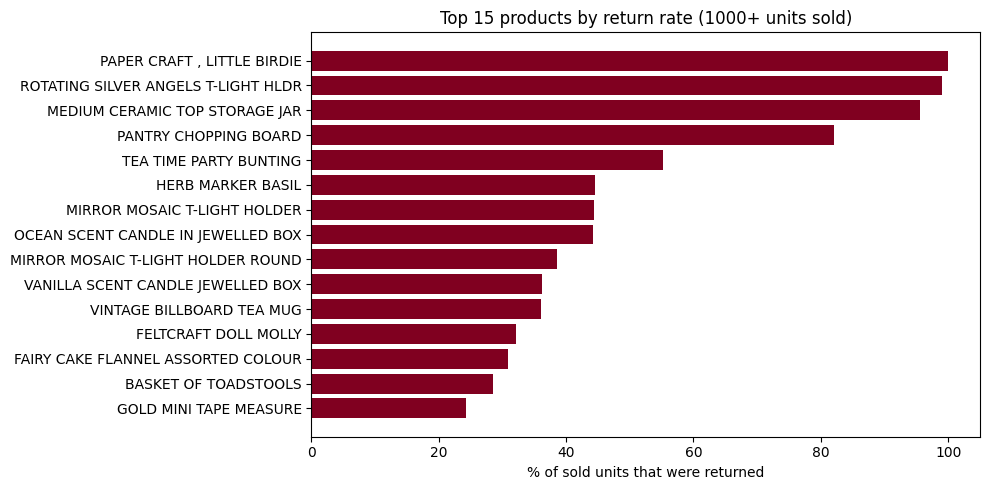

In [20]:
plt.figure(figsize=(10, 5))
plt.barh(returns["description"], returns["return_pct"], color=COLOR)
plt.gca().invert_yaxis()
plt.xlabel("% of sold units that were returned")
plt.title("Top 15 products by return rate (1000+ units sold)")
plt.tight_layout()
plt.savefig("images/product_returns.png", dpi=120)
plt.show()

The top 3 are not really "returned products". PAPER CRAFT LITTLE BIRDIE (80,995 units) and MEDIUM CERAMIC TOP STORAGE JAR (74,215 units) were each one huge order that was cancelled on the same day, probably a mistake. ROTATING SILVER ANGELS has one cancellation of 9,360 units on 2 December 2010, so the order itself was probably made before the data starts.

If I ignore them, products like TEA TIME PARTY BUNTING (55%) and HERB MARKER BASIL (45%) have a high return rate and it would be worth checking their quality or description.

## Summary

- I removed only 2% of the rows: service codes, wrong prices, stock corrections and duplicates
- revenue grows strongly from September to November, these 3 months bring 35% of all revenue
- 19% of customers (Champions) bring 62% of the revenue
- only about 1 in 5 new customers buys again in the next month, but 62% come back at some point during the year
- high cancellation numbers in January and December 2011 come from two huge cancelled orders, not from many small returns

**Main takeaway:** the shop depends on the Christmas season and a small group of loyal customers. The biggest opportunity is to turn first-time buyers into regular ones, ideally before the autumn season starts

In [21]:
conn.close()